# Resultados del proyecto: radiografías de baja resolución

Este notebook **muestra** los resultados que calculan los scripts del proyecto.
No vuelve a correr los modelos (salvo la sección opcional de Grad-CAM): lee
`resultados/paso2/resultados.json`, generado por `paso2_evaluar_base.py`.

**Cómo usarlo:** ábrelo en VS Code y pulsa **Run All** (Ejecutar todo).
Cada vez que vuelvas a correr el paso 2, ejecuta de nuevo el notebook y los gráficos se actualizan.
Las figuras también se guardan como PNG en `resultados/figuras/` para el informe.

In [1]:
import os, json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

AQUI = os.path.abspath("")                       # carpeta proyecto/
RESULTADOS = os.path.join(AQUI, "resultados", "paso2", "resultados.json")
FIGURAS = os.path.join(AQUI, "resultados", "figuras")
os.makedirs(FIGURAS, exist_ok=True)

with open(RESULTADOS, encoding="utf-8") as f:
    R = json.load(f)

MODELOS = list(R["modelos"])
CONDICIONES = {"nih_original": "NIH original", "nih_320": "NIH 320 px", "chex_valid": "CheXpert small"}
PATOLOGIAS = ["Atelectasis", "Cardiomegaly", "Consolidation", "Edema", "Effusion", "Pneumonia", "Pneumothorax"]
NOMBRE_CORTO = {"resnet50-res512-all": "ResNet-50 (512)", "densenet121-res224-nih": "DenseNet NIH",
                "densenet121-res224-chex": "DenseNet CheXpert", "densenet121-res224-all": "DenseNet all"}
corto = lambda m: NOMBRE_CORTO.get(m, m)

# Paleta categórica validada (una por condición, siempre en el mismo orden) y estilo sobrio
COLOR = {"nih_original": "#2a78d6", "nih_320": "#eb6834", "chex_valid": "#1baf7a"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e4e3df", "grid.linewidth": 0.8,
                     "axes.edgecolor": "#a3a29b", "axes.labelcolor": "#52514e", "xtick.color": "#52514e",
                     "ytick.color": "#52514e", "font.size": 10, "axes.titleweight": "bold"})

def guardar(fig, nombre):
    fig.savefig(os.path.join(FIGURAS, nombre), bbox_inches="tight", dpi=150)

print("Dispositivo:", R["device"], "|", R["env"].get("gpu", ""))
print("Imágenes evaluadas:", R["n_imagenes"])
if R["n_imagenes"]["nih_original"] < 25596:
    print("Nota: es una corrida parcial de NIH (--max-imgs). Para el informe usen la corrida completa.")

Dispositivo: cuda | NVIDIA GeForce RTX 4080
Imágenes evaluadas: {'nih_original': 25596, 'nih_320': 25596, 'chex_valid': 202}


## 1. Resumen: AUC promedio de las 7 patologías comunes

In [2]:
def auc_prom(m, c):
    return R["modelos"][m][c]["metricas"].get("PROMEDIO", {}).get("auc", np.nan)

filas = []
for m in MODELOS:
    f = R["modelos"][m]["fidelidad_nih"]
    filas.append({"Modelo": corto(m),
                  "NIH original": auc_prom(m, "nih_original"),
                  "NIH 320 px": auc_prom(m, "nih_320"),
                  "Brecha por resolución": auc_prom(m, "nih_original") - auc_prom(m, "nih_320"),
                  "CheXpert small": auc_prom(m, "chex_valid"),
                  "Decisiones que cambian (%)": f["pct_decisiones_cambian"],
                  "Spearman orig. vs 320": f["spearman_medio"]})
resumen = pd.DataFrame(filas).set_index("Modelo")
resumen.round(3)

,NIH original,NIH 320 px,Brecha por resolución,CheXpert small,Decisiones que cambian (%),Spearman orig. vs 320
Modelo,,,,,,
ResNet-50 (512),0.810,0.789,0.021,0.664,2.937,0.914
DenseNet NIH,0.691,0.691,-0.000,0.723,0.339,1.000
DenseNet CheXpert,0.637,0.636,0.000,0.824,0.195,1.000
DenseNet all,0.732,0.731,0.001,0.801,1.253,0.999


## 2. AUC promedio por modelo y condición

Cada grupo es un modelo; cada color, una condición. La comparación clave para la
**resolución** es azul contra naranjo (mismas imágenes de NIH); para el **cambio de
hospital**, cualquiera de los dos contra el verde (CheXpert).

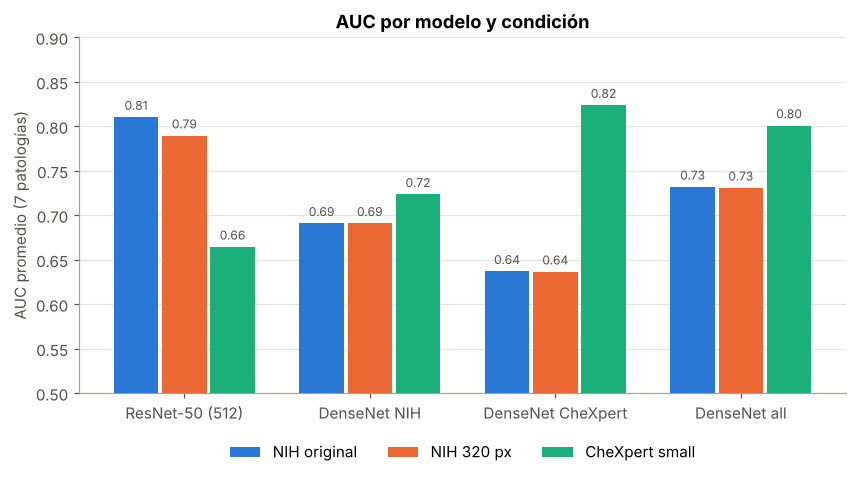

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.2))
x = np.arange(len(MODELOS)); w = 0.26
for i, (c, nombre) in enumerate(CONDICIONES.items()):
    vals = [auc_prom(m, c) for m in MODELOS]
    barras = ax.bar(x + (i - 1) * w, vals, w - 0.02, color=COLOR[c], label=nombre, zorder=3)
    for b, v in zip(barras, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.005, f"{v:.2f}", ha="center", va="bottom", fontsize=8, color="#52514e")
ax.set_xticks(x, [corto(m) for m in MODELOS])
ax.set_ylim(0.5, 0.9); ax.set_ylabel("AUC promedio (7 patologías)")
ax.set_title("AUC por modelo y condición")
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1))
guardar(fig, "1_auc_por_modelo.png"); plt.show()

## 3. ¿Dónde se pierde más: por resolución o por cambiar de hospital?

- **Pérdida por resolución** = AUC NIH original − AUC NIH 320 px (mismas imágenes).
- **Pérdida por cambiar de hospital** = AUC NIH original − AUC CheXpert small.

Un valor negativo significa que el modelo rinde **mejor** en CheXpert (por ejemplo, el
DenseNet entrenado con CheXpert, que "juega en casa").

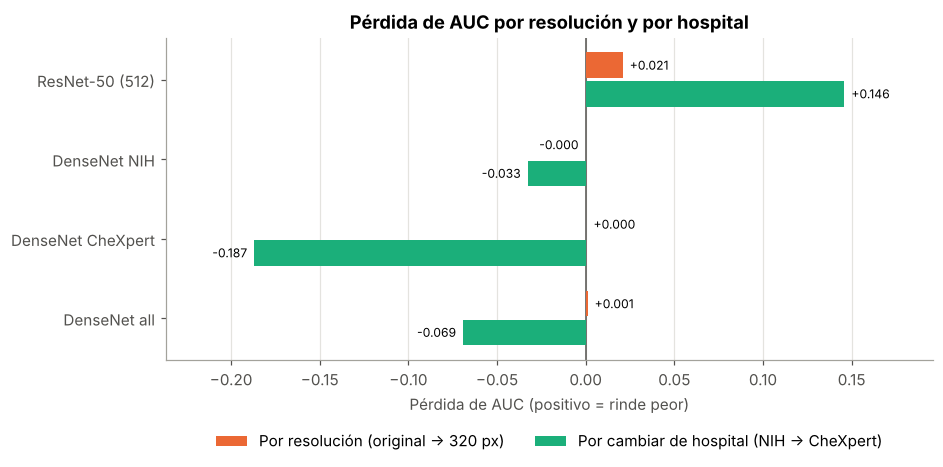

In [4]:
res = [auc_prom(m, "nih_original") - auc_prom(m, "nih_320") for m in MODELOS]
hos = [auc_prom(m, "nih_original") - auc_prom(m, "chex_valid") for m in MODELOS]
fig, ax = plt.subplots(figsize=(9, 3.8))
y = np.arange(len(MODELOS)); h = 0.36
ax.barh(y - h / 2, res, h - 0.04, color=COLOR["nih_320"], label="Por resolución (original → 320 px)", zorder=3)
ax.barh(y + h / 2, hos, h - 0.04, color=COLOR["chex_valid"], label="Por cambiar de hospital (NIH → CheXpert)", zorder=3)
for yi, v in zip(y - h / 2, res): ax.text(v + (0.004 if v >= 0 else -0.004), yi, f"{v:+.3f}", va="center", ha="left" if v >= 0 else "right", fontsize=8)
for yi, v in zip(y + h / 2, hos): ax.text(v + (0.004 if v >= 0 else -0.004), yi, f"{v:+.3f}", va="center", ha="left" if v >= 0 else "right", fontsize=8)
ax.axvline(0, color="#52514e", lw=1)
lo, hi = min(res + hos + [0]), max(res + hos + [0])
ax.set_xlim(lo - 0.05, hi + 0.05)
ax.set_yticks(y, [corto(m) for m in MODELOS]); ax.invert_yaxis()
ax.set_xlabel("Pérdida de AUC (positivo = rinde peor)"); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title("Pérdida de AUC por resolución y por hospital")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)
guardar(fig, "2_perdida_resolucion_vs_hospital.png"); plt.show()

## 4. AUC por patología, con intervalos de confianza del 95 %

Las barras de error son los IC95 % por bootstrap a nivel de paciente. Si dos intervalos se
superponen mucho, la diferencia puede ser ruido.

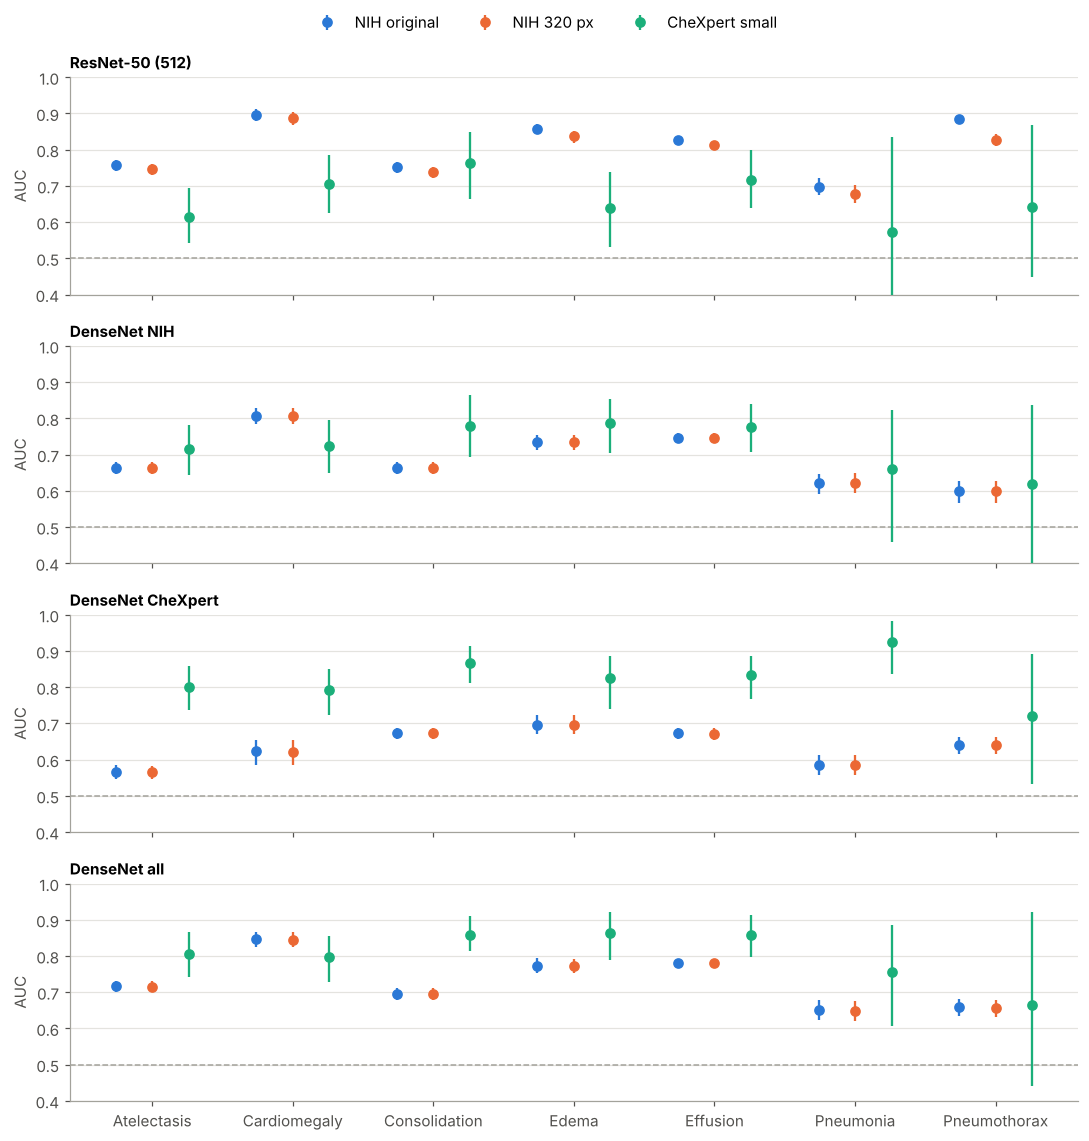

In [5]:
def auc_pat(m, c, p):
    d = R["modelos"][m][c]["metricas"].get(p)
    return (d["auc"], d["auc_ic95"][0], d["auc_ic95"][1]) if d else (np.nan, np.nan, np.nan)

fig, axes = plt.subplots(len(MODELOS), 1, figsize=(10, 2.6 * len(MODELOS)), sharex=True)
x = np.arange(len(PATOLOGIAS)); w = 0.26
for ax, m in zip(np.atleast_1d(axes), MODELOS):
    for i, c in enumerate(CONDICIONES):
        v = np.array([auc_pat(m, c, p) for p in PATOLOGIAS])
        ax.errorbar(x + (i - 1) * w, v[:, 0], yerr=[v[:, 0] - v[:, 1], v[:, 2] - v[:, 0]], fmt="o", ms=6,
                    color=COLOR[c], ecolor=COLOR[c], elinewidth=1.5, capsize=0, label=CONDICIONES[c], zorder=3)
    ax.axhline(0.5, color="#a3a29b", lw=1, ls="--")
    ax.set_ylim(0.4, 1.0); ax.set_ylabel("AUC"); ax.set_title(corto(m), loc="left", fontsize=10)
np.atleast_1d(axes)[-1].set_xticks(x, PATOLOGIAS, rotation=0)
fig.tight_layout(rect=(0, 0, 1, 0.97))
h_, l_ = np.atleast_1d(axes)[0].get_legend_handles_labels()
fig.legend(h_, l_, frameon=False, ncol=3, loc="upper center")
guardar(fig, "3_auc_por_patologia_ic95.png"); plt.show()

## 5. Mapa de calor: AUC por patología y modelo

Una escala de un solo color: más oscuro = mejor AUC. Permite ver de un vistazo qué
patologías son difíciles para todos los modelos.

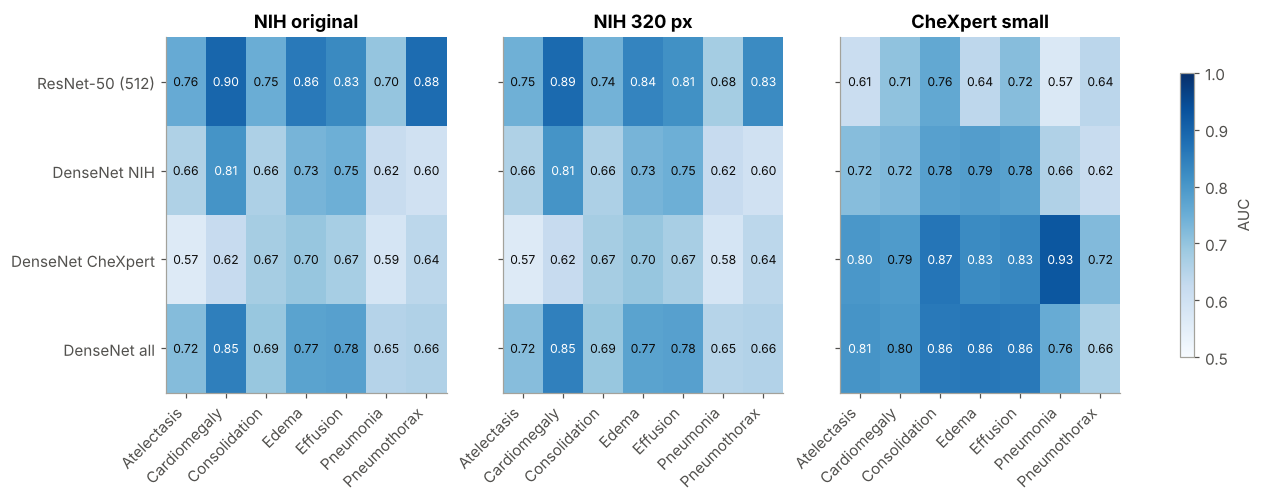

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
for ax, (c, nombre) in zip(axes, CONDICIONES.items()):
    M = np.array([[auc_pat(m, c, p)[0] for p in PATOLOGIAS] for m in MODELOS])
    im = ax.imshow(M, cmap="Blues", vmin=0.5, vmax=1.0, aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            if not np.isnan(M[i, j]):
                ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=8,
                        color="white" if M[i, j] > 0.8 else "#0b0b0b")
    ax.set_xticks(range(len(PATOLOGIAS)), PATOLOGIAS, rotation=45, ha="right")
    ax.set_title(nombre); ax.grid(False)
axes[0].set_yticks(range(len(MODELOS)), [corto(m) for m in MODELOS])
fig.colorbar(im, ax=axes, shrink=0.8, label="AUC")
guardar(fig, "4_mapa_calor_auc.png"); plt.show()

## 6. Sensibilidad y especificidad en el umbral de cada modelo (CheXpert small)

El AUC mide si el modelo **ordena** bien a los pacientes; la sensibilidad y especificidad
miden cuántos acierta **con su umbral de decisión**. Un modelo puede tener buen AUC y aun
así casi nunca decir "positivo" en otro hospital: sus umbrales quedaron descalibrados.

In [7]:
filas = []
for m in MODELOS:
    for p in PATOLOGIAS:
        d = R["modelos"][m]["chex_valid"]["metricas"].get(p)
        if d:
            filas.append({"Modelo": corto(m), "Patología": p, "Sensibilidad": d["sensibilidad"],
                          "Especificidad": d["especificidad"], "AUC": d["auc"], "Brier": d["brier"]})
se = pd.DataFrame(filas)
tabla = se.pivot(index="Patología", columns="Modelo", values="Sensibilidad")
print("Sensibilidad en CheXpert small (0 = no detecta ningún caso; 1 = los detecta todos)")
tabla.round(2)

Sensibilidad en CheXpert small (0 = no detecta ningún caso; 1 = los detecta todos)


Modelo,DenseNet CheXpert,DenseNet NIH,DenseNet all,ResNet-50 (512)
Patología,,,,
Atelectasis,0.99,0.93,1.00,0.01
Cardiomegaly,0.89,0.33,0.97,0.00
Consolidation,1.00,0.97,1.00,0.06
Edema,0.98,0.62,0.98,0.00
Effusion,0.94,0.86,0.98,0.06
Pneumonia,1.00,1.00,1.00,0.12
Pneumothorax,0.57,0.86,1.00,0.00


## 7. Fidelidad: ¿cuánto cambian las respuestas al reducir la imagen?

Compara, **para las mismas imágenes de NIH**, lo que responde cada modelo con la versión
original y con la de 320 px. No usa etiquetas: mide solo cuánto se parecen las respuestas.

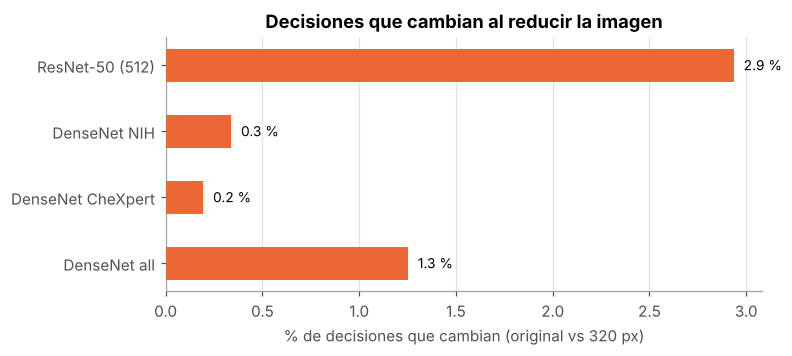

,Diferencia media de probabilidad,% de decisiones que cambian,Spearman medio
ResNet-50 (512),0.042,2.937,0.914
DenseNet NIH,0.002,0.339,1.000
DenseNet CheXpert,0.002,0.195,1.000
DenseNet all,0.008,1.253,0.999


In [8]:
fid = pd.DataFrame({corto(m): R["modelos"][m]["fidelidad_nih"] for m in MODELOS}).T
fid.columns = ["Diferencia media de probabilidad", "% de decisiones que cambian", "Spearman medio"]
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(fid.index, fid["% de decisiones que cambian"], color=COLOR["nih_320"], height=0.5, zorder=3)
for i, v in enumerate(fid["% de decisiones que cambian"]):
    ax.text(v + 0.05, i, f"{v:.1f} %", va="center", fontsize=9)
ax.invert_yaxis(); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("% de decisiones que cambian (original vs 320 px)")
ax.set_title("Decisiones que cambian al reducir la imagen")
guardar(fig, "5_fidelidad.png"); plt.show()
fid.round(3)

## 8. Grad-CAM: ¿dónde mira el modelo? (opcional, usa la GPU)

Muestra radiografías reales de NIH test con una caja dibujada por radiólogos (lista de NIH) y el
mapa Grad-CAM del ResNet-50 en la imagen **original** y en la de **320 px**. Sirve para ver si al
reducir la resolución el modelo sigue mirando la lesión. Ajusta `CARPETA_NIH` si tu NIH está en otro lugar.

In [9]:
CARPETA_NIH = r"C:\Users\mines\Downloads\torchxrayvision-1.5.7\NIH"
PATOLOGIA = "Cardiomegaly"        # también: Effusion, Atelectasis, Pneumothorax, Pneumonia
N_EJEMPLOS = 3

import torch, torch.nn.functional as F, cv2
sys.path.insert(0, AQUI)
import comun_proyecto as cp
import torchxrayvision as xrv

if not os.path.isdir(os.path.join(CARPETA_NIH, "images")):
    print("No se encontró", os.path.join(CARPETA_NIH, "images"), "- ajusta CARPETA_NIH para ver esta sección.")
else:
    device = "cuda" if torch.cuda.is_available() else "cpu"
    modelo, targets, _ = cp.cargar_modelo("resnet50-res512-all", device)
    ti = targets.index(PATOLOGIA)
    cajas = pd.read_csv(os.path.join(cp.RAIZ, "torchxrayvision", "data", "BBox_List_2017.csv.gz"))
    cajas.columns = ["img", "label", "x", "y", "w", "h"] + list(cajas.columns[6:])
    test = cp.leer_lista(os.path.join(CARPETA_NIH, "test_list.txt"))
    cajas = cajas[(cajas.label == PATOLOGIA) & cajas.img.isin(test)].head(N_EJEMPLOS)

    def gradcam(img1024, res):
        img = cv2.resize(img1024, (res, res), interpolation=cv2.INTER_AREA)
        x = torch.from_numpy(xrv.utils.normalize(img.astype(np.float32), 255))[None, None].to(device)
        act = {}
        h = modelo.model.layer4.register_forward_hook(lambda m_, i_, o: act.__setitem__("a", o))
        x.requires_grad_(True)
        with cp.bench.quiet():
            y = modelo(x)
        h.remove()
        g = torch.autograd.grad(y[0, ti], act["a"])[0][0]
        cam = F.relu((g.mean((1, 2))[:, None, None] * act["a"][0]).sum(0))
        cam = F.interpolate(cam[None, None], size=(1024, 1024), mode="bilinear")[0, 0].detach().cpu().numpy()
        return (cam - cam.min()) / (cam.max() - cam.min() + 1e-8), float(y[0, ti])

    if len(cajas) == 0:
        print("No hay imágenes de test con caja para", PATOLOGIA)
    fig, axes = plt.subplots(len(cajas), 3, figsize=(11, 3.8 * len(cajas)), squeeze=False)
    for fila, (_, c) in zip(axes, cajas.iterrows()):
        img = cv2.imread(os.path.join(CARPETA_NIH, "images", c.img), cv2.IMREAD_GRAYSCALE)
        for ax, (titulo, res) in zip(fila, [("Imagen", None), ("Grad-CAM original (512)", 512), ("Grad-CAM 320 px", 320)]):
            ax.imshow(img, cmap="gray"); ax.axis("off")
            if res:
                cam, p = gradcam(img, res)
                ax.imshow(cam, cmap="jet", alpha=0.4)
                titulo += f"\nprob. {PATOLOGIA}: {p:.2f}"
            ax.add_patch(plt.Rectangle((c.x, c.y), c.w, c.h, fill=False, ec="#1baf7a", lw=2))
            ax.set_title(titulo, fontsize=9)
        fila[0].set_title(f"{c.img}\n(caja verde = radiólogo)", fontsize=9)
    fig.tight_layout(); guardar(fig, f"6_gradcam_{PATOLOGIA}.png"); plt.show()

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


No se encontró C:\Users\mines\Downloads\torchxrayvision-1.5.7\NIH/images - ajusta CARPETA_NIH para ver esta sección.


## 10. Técnicas para recuperar precisión sin entrenar (paso 2b)

Sobre el ResNet-50 original con imágenes de 320 px: mejor interpolación, AdaBN (estadísticas de
normalización del dominio de destino, sin etiquetas), TTA (promedio de 5 variantes) y
recalibración de umbrales. Se lee de `resultados/paso2b/tecnicas.json` (script
`paso2b_tecnicas_sin_entrenar.py`).

- **Brecha recuperada** (NIH) = (AUC técnica − AUC 320 base) / (AUC original − AUC 320 base).
  0 % = no ayuda; 100 % = rinde como con la imagen original; negativo = empeora.
- La recalibración **no cambia el AUC** (el orden de los pacientes es el mismo); su efecto se ve
  en la sensibilidad y la especificidad.

In [10]:
TEC = os.path.join(AQUI, "resultados", "paso2b", "tecnicas.json")
if not os.path.exists(TEC):
    print("Aún no hay resultados del paso 2b. Ejecuten proyecto\\paso2b_tecnicas_sin_entrenar.py y vuelvan a correr esta celda.")
else:
    with open(TEC, encoding="utf-8") as f:
        T = json.load(f)
    def media(d, clave):
        return float(np.mean([v[clave] for k, v in d["metricas"].items() if k != "PROMEDIO"]))
    filas = []
    for k in T["nih"]:
        fila = {"Técnica": k, "AUC NIH": T["nih"][k]["metricas"]["PROMEDIO"]["auc"],
                "Brecha recuperada (%)": T["brecha_nih"]["recuperada_pct"].get(k, np.nan),
                "Sensibilidad NIH": media(T["nih"][k], "sensibilidad"),
                "Especificidad NIH": media(T["nih"][k], "especificidad")}
        if k in T["chex"]:
            fila.update({"AUC CheXpert": T["chex"][k]["metricas"]["PROMEDIO"]["auc"],
                         "Sensibilidad CheXpert": media(T["chex"][k], "sensibilidad"),
                         "Especificidad CheXpert": media(T["chex"][k], "especificidad")})
        filas.append(fila)
    tec = pd.DataFrame(filas).set_index("Técnica")
    print("Modelo:", T["modelo"], "| imágenes:", T["n_imagenes"])
    display(tec.round(3))

Modelo: resnet50-res512-all | imágenes: {'nih_test': 25596, 'chex_valid': 202, 'adapt_nih': 5000, 'adapt_chex': 5000}


,AUC NIH,Brecha recuperada (%),Sensibilidad NIH,Especificidad NIH,AUC CheXpert,Sensibilidad CheXpert,Especificidad CheXpert
Técnica,,,,,,,
original (512),0.810,NaN,0.155,0.979,NaN,NaN,NaN
320 base (bilineal interna),0.789,0.000,0.035,0.997,0.664,0.038,0.998
320 interp. vecino,0.806,77.790,0.092,0.991,0.697,0.002,1.000
320 interp. bicubica,0.797,39.028,0.050,0.996,0.654,0.007,0.996
320 interp. lanczos,0.800,51.004,0.058,0.995,0.648,0.007,0.998
320 TTA,0.786,-17.686,0.026,0.998,0.674,0.006,0.999
320 AdaBN,0.805,76.604,0.124,0.982,0.790,0.022,1.000
320 AdaBN + TTA,0.807,84.743,0.095,0.987,0.782,0.011,1.000
320 umbrales recalibrados,0.789,0.000,0.857,0.533,0.664,0.598,0.639


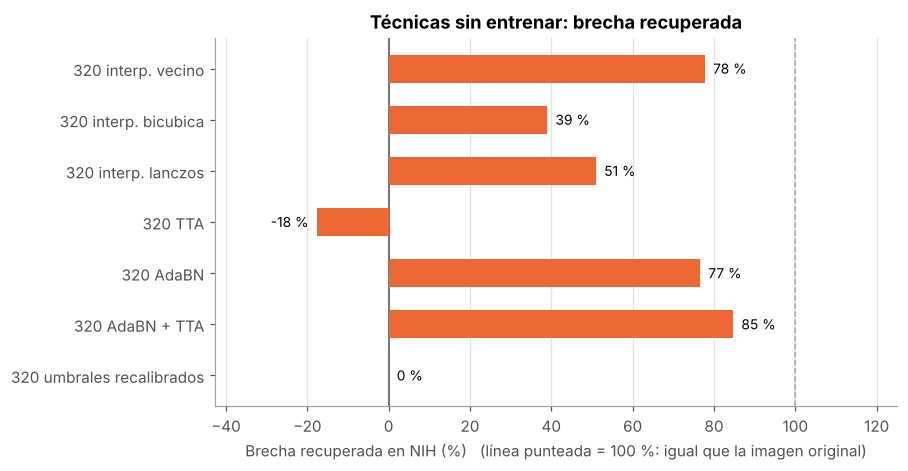

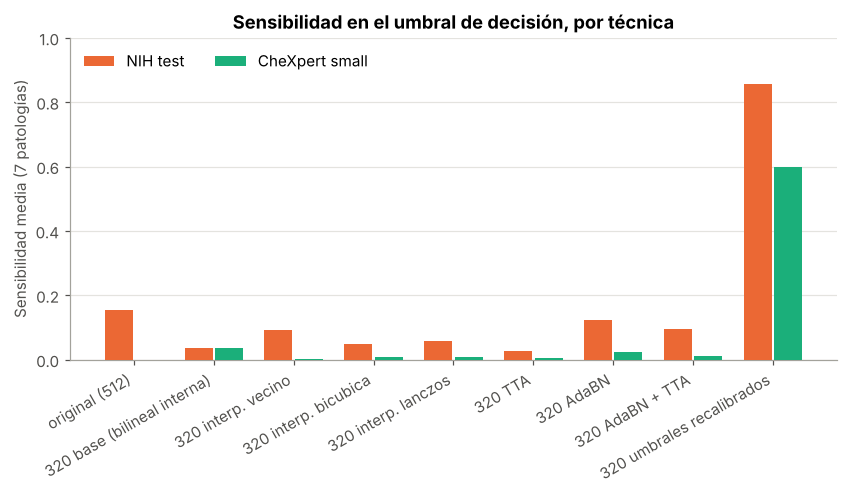

In [11]:
if os.path.exists(TEC):
    b = tec["Brecha recuperada (%)"].drop(index=["320 base (bilineal interna)"], errors="ignore").dropna()
    fig, ax = plt.subplots(figsize=(8, 0.45 * len(b) + 1.2))
    ax.barh(b.index, b.values, color=COLOR["nih_320"], height=0.55, zorder=3)
    for i, v in enumerate(b.values):
        ax.text(v + (2 if v >= 0 else -2), i, f"{v:.0f} %", va="center", ha="left" if v >= 0 else "right", fontsize=9)
    ax.axvline(0, color="#52514e", lw=1); ax.axvline(100, color="#a3a29b", lw=1, ls="--")
    ax.invert_yaxis(); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
    lo, hi = min(b.min(), 0), max(b.max(), 100)
    ax.set_xlim(lo - 25, hi + 25)
    ax.set_xlabel("Brecha recuperada en NIH (%)   (línea punteada = 100 %: igual que la imagen original)")
    ax.set_title("Técnicas sin entrenar: brecha recuperada")
    guardar(fig, "7_tecnicas_brecha_recuperada.png"); plt.show()

    s = tec[["Sensibilidad NIH", "Sensibilidad CheXpert"]]
    fig, ax = plt.subplots(figsize=(9, 3.8))
    x = np.arange(len(s)); w = 0.38
    ax.bar(x - w / 2, s["Sensibilidad NIH"], w - 0.03, color=COLOR["nih_320"], label="NIH test", zorder=3)
    ax.bar(x + w / 2, s["Sensibilidad CheXpert"], w - 0.03, color=COLOR["chex_valid"], label="CheXpert small", zorder=3)
    ax.set_xticks(x, s.index, rotation=30, ha="right"); ax.set_ylim(0, 1)
    ax.set_ylabel("Sensibilidad media (7 patologías)")
    ax.set_title("Sensibilidad en el umbral de decisión, por técnica")
    ax.legend(frameon=False, ncol=2, loc="upper left")
    guardar(fig, "8_tecnicas_sensibilidad.png"); plt.show()

## 11. Hallazgos automáticos (se recalculan con cada corrida)

In [12]:
mejor_nih = resumen["NIH original"].idxmax()
mejor_chex = resumen["CheXpert small"].idxmax()
mayor_brecha = resumen["Brecha por resolución"].idxmax()
print(f"- Mejor modelo en NIH original: {mejor_nih} (AUC {resumen.loc[mejor_nih, 'NIH original']:.3f})")
print(f"- Mejor modelo en CheXpert small: {mejor_chex} (AUC {resumen.loc[mejor_chex, 'CheXpert small']:.3f})")
print(f"- Mayor pérdida por resolución (original → 320 px): {mayor_brecha} "
      f"({resumen.loc[mayor_brecha, 'Brecha por resolución']:+.3f} AUC, "
      f"{resumen.loc[mayor_brecha, 'Decisiones que cambian (%)']:.1f} % de decisiones cambian)")
for m in resumen.index:
    caida = resumen.loc[m, "NIH original"] - resumen.loc[m, "CheXpert small"]
    print(f"- {m}: NIH → CheXpert {-caida:+.3f} AUC")
print(f"\nFiguras guardadas en: {FIGURAS}")

- Mejor modelo en NIH original: ResNet-50 (512) (AUC 0.810)
- Mejor modelo en CheXpert small: DenseNet CheXpert (AUC 0.824)
- Mayor pérdida por resolución (original → 320 px): ResNet-50 (512) (+0.021 AUC, 2.9 % de decisiones cambian)
- ResNet-50 (512): NIH → CheXpert -0.146 AUC
- DenseNet NIH: NIH → CheXpert +0.033 AUC
- DenseNet CheXpert: NIH → CheXpert +0.187 AUC
- DenseNet all: NIH → CheXpert +0.069 AUC

Figuras guardadas en: /root/txv/proyecto/resultados/figuras
